# Laboratorio 3: La tarea de clasificación - Ruta Alpes

**Caso:** Ruta Alpes, aplicación de asistencia de conducción con recomendación de cupones.

**Integrantes:** Juan Camilo Panadero - Jose Luis Parra

**Objetivo:** Construir y comparar modelos de clasificación (regresión logística, árbol de decisión y Random Forest) para predecir si un conductor acepta un cupón de **Cafetería** o de **Restaurante(<20)**, evaluar el efecto del desbalance de clases y el balanceo con SMOTE, identificar las variables más relevantes, y generar predicciones sobre un conjunto de datos no etiquetado.

## 0. Importación de librerías requeridas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              f1_score, recall_score, precision_score)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from importlib.metadata import version
print(f"Pandas: {version('pandas')} | Scikit-learn: {version('scikit-learn')} | imbalanced-learn: {version('imbalanced-learn')}")

RANDOM_STATE = 42
pd.set_option('display.max_columns', 30)

Pandas: 2.3.3 | Scikit-learn: 1.9.0 | imbalanced-learn: 0.14.2


## 1. Comprensión del problema

Ruta Alpes recomienda cupones (restaurantes, cafeterías, bares, comida para llevar) a conductores mientras se desplazan, pero enviar la misma oferta a todos genera baja efectividad y, a veces, molestia. La empresa quiere anticipar, a partir del contexto del trayecto (destino, clima, hora, acompañante) y del perfil del conductor (edad, ingreso, hábitos de consumo), si una persona aceptará un cupón determinado.

Este laboratorio trabaja sobre dos tipos de cupón, que se modelan por separado porque no hay razón para esperar que el mismo conjunto de factores explique la aceptación de ambos:

- **Cafetería**: una compra pequeña, de bajo compromiso.
- **Restaurante(<20)**: una comida de gasto promedio menor a $20 por persona, que implica más tiempo y una decisión distinta (p. ej., desviarse de la ruta).

La pregunta que orienta el análisis es:

> **¿Qué tan bien se puede anticipar, a partir del contexto de conducción y del perfil del conductor, si aceptará un cupón de Cafetería o de Restaurante(<20)?**

A diferencia de los laboratorios anteriores, aquí la variable objetivo (`acepta_cupon`) es categórica y binaria, por lo que se trata de un problema de **clasificación**, no de regresión.

## 2. Comprensión de los datos

In [2]:
data_raw = pd.read_excel('Data/Lab3_Datos.xlsx')
print(data_raw.shape)
data_raw.head()

(12664, 26)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


El conjunto completo reúne escenarios de cinco tipos de cupón distintos (Bar, Cafetería, Comida para llevar, Restaurante(<20) y Restaurante(20-50)). Para este laboratorio solo interesan dos, así que se separan en dos subconjuntos independientes desde el inicio: todo el análisis de calidad, limpieza y modelado se hace por separado para cada uno, porque son dos problemas de clasificación distintos (variables distintas pueden importar para cada uno) y porque mezclarlos introduciría una variable (`cupon`) que ya no tendría sentido dentro de cada subconjunto.

In [3]:
cafeteria_raw = data_raw[data_raw['cupon'] == 'Cafetería'].drop(columns='cupon').reset_index(drop=True)
restaurante_raw = data_raw[data_raw['cupon'] == 'Restaurante(<20)'].drop(columns='cupon').reset_index(drop=True)

print(f"Cafetería:         {cafeteria_raw.shape[0]} filas, {cafeteria_raw.shape[1]} columnas")
print(f"Restaurante(<20):  {restaurante_raw.shape[0]} filas, {restaurante_raw.shape[1]} columnas")

Cafetería:         3986 filas, 25 columnas
Restaurante(<20):  2776 filas, 25 columnas


### Distribución de la variable objetivo

Antes de revisar la calidad de los datos, es importante ver qué tan balanceada está `acepta_cupon` en cada subconjunto, porque eso condiciona cómo se debe entrenar y evaluar cada modelo.

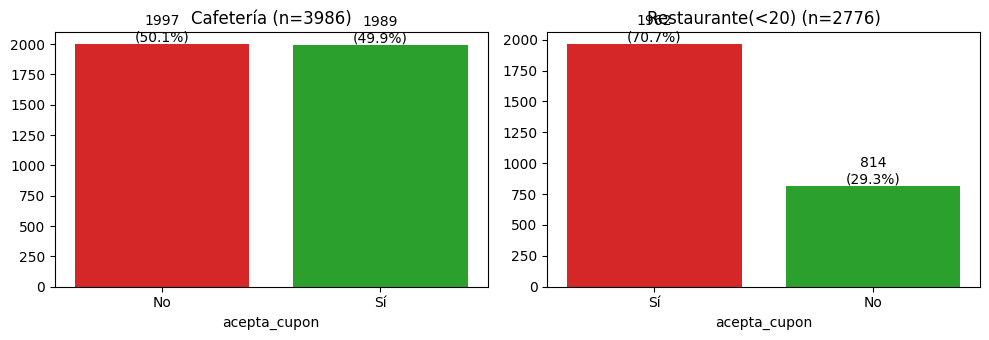

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (nombre, df) in zip(axes, [('Cafetería', cafeteria_raw), ('Restaurante(<20)', restaurante_raw)]):
    conteo = df['acepta_cupon'].value_counts()
    porcentaje = df['acepta_cupon'].value_counts(normalize=True) * 100
    ax.bar(conteo.index, conteo.values, color=['#d62728', '#2ca02c'])
    for i, (idx, val) in enumerate(conteo.items()):
        ax.text(i, val, f"{val}\n({porcentaje[idx]:.1f}%)", ha='center', va='bottom')
    ax.set_title(f'{nombre} (n={len(df)})')
    ax.set_xlabel('acepta_cupon')
plt.tight_layout()
plt.show()

### Calidad de los datos

Revisamos las cuatro dimensiones de calidad —completitud, unicidad, consistencia y validez— sobre el conjunto completo cuando aplica (algunos problemas, como `vehiculo`, afectan a los cinco tipos de cupón) y sobre cada subconjunto cuando corresponde.

#### Completitud

In [5]:
print("Valores nulos - Cafetería:")
print(cafeteria_raw.isna().sum()[cafeteria_raw.isna().sum() > 0])
print()
print("Valores nulos - Restaurante(<20):")
print(restaurante_raw.isna().sum()[restaurante_raw.isna().sum() > 0])

Valores nulos - Cafetería:
vehiculo                           3949
frecuencia_bar                       37
frecuencia_cafeteria                 72
frecuencia_comida_para_llevar        57
frecuencia_restaurante_menos_20      50
frecuencia_restaurante_20_a_50       55
dtype: int64

Valores nulos - Restaurante(<20):
vehiculo                           2751
frecuencia_bar                       23
frecuencia_cafeteria                 47
frecuencia_comida_para_llevar        34
frecuencia_restaurante_menos_20      27
frecuencia_restaurante_20_a_50       43
dtype: int64


**Cómo se lee.** Ambos subconjuntos tienen el mismo patrón de ausencias: `vehiculo` (que se revisa más abajo) y las cinco variables de frecuencia de consumo, cada una con menos del 2% de nulos. Al ser un porcentaje bajo y tratarse de variables categóricas ordinales, la estrategia adecuada (según la tabla de orientación de la práctica de limpieza) es imputar con la moda, dentro del pipeline, en la Sección 4.

#### Unicidad

In [6]:
print(f"Filas duplicadas en Cafetería:        {cafeteria_raw.duplicated().sum()}")
print(f"Filas duplicadas en Restaurante(<20):   {restaurante_raw.duplicated().sum()}")

Filas duplicadas en Cafetería:        7
Filas duplicadas en Restaurante(<20):   7


**Cómo se lee.** Ninguno de los dos subconjuntos tiene un identificador de conductor o de escenario, así que la única verificación posible es la de filas completamente idénticas (no hay forma de detectar "duplicados lógicos" sin un ID). Ambos subconjuntos tienen algunas: se eliminan en la Sección 3, antes de particionar en entrenamiento y prueba.

#### Consistencia

Revisamos si alguna columna categórica tiene variantes de formato (mayúsculas, espacios) que deberían representar la misma categoría.

In [7]:
columnas_categoricas = cafeteria_raw.select_dtypes(include='object').columns

inconsistencias = {}
for col in columnas_categoricas:
    valores = cafeteria_raw[col].dropna().unique()
    normalizados = {str(v).strip().upper() for v in valores}
    if len(normalizados) != len(valores):
        inconsistencias[col] = sorted(valores, key=str)

if inconsistencias:
    print("Columnas con posibles variantes de formato:")
    for col, valores in inconsistencias.items():
        print(f"  {col}: {valores}")
else:
    print("No se encontraron variantes de mayúsculas/espacios en ninguna columna categórica.")

No se encontraron variantes de mayúsculas/espacios en ninguna columna categórica.


**Cómo se lee.** A diferencia del caso de `FrenteMar` visto en la práctica de calidad de datos, aquí no aparece ninguna variante de formato: cada categoría tiene una única forma de escritura en todo el conjunto. No se requiere ninguna corrección de consistencia.

#### Validez

Comparamos los valores observados de cada variable con el dominio documentado en el diccionario de datos (Sección "Conjunto de datos" del enunciado), y verificamos que `temperatura` solo tome los tres valores fijos que describe el diccionario (30, 55 y 80 °F).

In [8]:
DOMINIOS_ESPERADOS = {
    'destino': {'Casa', 'Sin lugar urgente', 'Trabajo'},
    'acompanante': {'Solo', 'Amigo(s)', 'Hijo(s)', 'Pareja'},
    'clima': {'Soleado', 'Lluvioso', 'Nevado'},
    'vigencia_cupon': {'2 horas', '1 día'},
    'genero': {'Femenino', 'Masculino'},
    'estado_civil': {'Soltero(a)', 'Casado(a)', 'Unión libre', 'Divorciado(a)', 'Viudo(a)'},
    'tiene_hijos': {'Sí', 'No'},
    'misma_direccion': {'Sí', 'No'},
    'direccion_opuesta': {'Sí', 'No'},
    'tiempo_cupon_mayor_15min': {'Sí', 'No'},
    'tiempo_cupon_mayor_25min': {'Sí', 'No'},
}

problemas_validez = False
for col, dominio in DOMINIOS_ESPERADOS.items():
    valores_reales = set(cafeteria_raw[col].dropna().unique()) | set(restaurante_raw[col].dropna().unique())
    fuera_de_dominio = valores_reales - dominio
    if fuera_de_dominio:
        problemas_validez = True
        print(f"{col}: valores fuera del dominio esperado -> {fuera_de_dominio}")

if not problemas_validez:
    print("Todas las columnas categóricas revisadas están dentro del dominio documentado.")

print()
print("Valores únicos de temperatura:", sorted(data_raw['temperatura'].unique()), "(esperado: {30, 55, 80})")

Todas las columnas categóricas revisadas están dentro del dominio documentado.

Valores únicos de temperatura: [np.int64(30), np.int64(55), np.int64(80)] (esperado: {30, 55, 80})


**Cómo se lee.** No se encontraron valores fuera del dominio documentado en ninguna de las columnas categóricas revisadas, y `temperatura` solo toma los tres valores que describe el diccionario. A diferencia del caso de `Vista` en la práctica de calidad de datos (que sí tenía valores negativos y repdígitos), este conjunto de datos no presenta problemas de validez.

**Sobre valores atípicos.** El análisis tradicional de atípicos (boxplots, rango intercuartílico) aplica a variables cuantitativas continuas, y este conjunto prácticamente no tiene ninguna: la única columna numérica es `temperatura`, y por diseño de la encuesta solo toma tres valores fijos (30, 55 y 80 °F, verificado arriba), por lo que no puede presentar valores atípicos en el sentido estadístico habitual. En variables categóricas y ordinales -que son casi todas las de este conjunto- el equivalente a un valor atípico es una categoría fuera del dominio esperado o con una frecuencia anormalmente rara, que es exactamente lo que ya cubrió la revisión de dominios de esta sección (ninguna categoría fuera de lo documentado) y los conteos de la sección de Completitud y Unicidad.

#### Variables redundantes o poco informativas

Más allá de las cuatro dimensiones, vale la pena revisar tres variables que, por su propia definición, son sospechosas de no aportar nada al modelo.

In [9]:
print("`vehiculo`: porcentaje de valores nulos")
print((data_raw['vehiculo'].isna().mean() * 100).round(1), "%")
print()
print("`tiempo_cupon_mayor_5min`: valores únicos presentes")
print(data_raw['tiempo_cupon_mayor_5min'].value_counts(dropna=False))
print()
print("`misma_direccion` vs. `direccion_opuesta` (tabla de contingencia):")
print(pd.crosstab(data_raw['misma_direccion'], data_raw['direccion_opuesta']))
print()
print("`tiempo_cupon_mayor_15min` vs. `tiempo_cupon_mayor_25min` (tabla de contingencia):")
print(pd.crosstab(data_raw['tiempo_cupon_mayor_15min'], data_raw['tiempo_cupon_mayor_25min']))

`vehiculo`: porcentaje de valores nulos
99.1 %

`tiempo_cupon_mayor_5min`: valores únicos presentes
tiempo_cupon_mayor_5min
Sí    12664
Name: count, dtype: int64

`misma_direccion` vs. `direccion_opuesta` (tabla de contingencia):


direccion_opuesta    No    Sí
misma_direccion              
No                    0  9944
Sí                 2720     0

`tiempo_cupon_mayor_15min` vs. `tiempo_cupon_mayor_25min` (tabla de contingencia):


tiempo_cupon_mayor_25min    No    Sí
tiempo_cupon_mayor_15min            
No                        5551     0
Sí                        5602  1511


**Cómo se lee.** `vehiculo` tiene nulos en más del 99% de las filas -casi nadie reportó esta variable, así que no puede aportar nada útil y no vale la pena ni imputarla-. `tiempo_cupon_mayor_5min` tiene un único valor posible (`Sí`) en **todo** el conjunto (no solo en estos dos subconjuntos): su varianza es cero, por lo que no distingue nada y cualquier modelo la ignoraría de todas formas. Y `misma_direccion` y `direccion_opuesta` son perfectamente complementarias (`misma_direccion = Sí` ocurre exactamente cuando `direccion_opuesta = No`, y viceversa): son la misma información contada dos veces, así que basta con conservar una. Estas tres observaciones se traducen directamente en decisiones de limpieza en la siguiente sección.

Hay un cuarto caso, más sutil, que **no** se elimina pero vale la pena anotar: `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` están perfectamente anidadas (nunca hay un caso de más de 25 minutos que no sea también de más de 15; la celda "No"/"Sí" de la tabla de contingencia queda en cero). Juntas equivalen a una sola variable ordinal de tres niveles (≤15 min, entre 15 y 25 min, >25 min) repartida en dos columnas binarias. No son exactamente redundantes como el par anterior -cada una aporta información que la otra no tiene por separado-, pero sí podrían resumirse en una sola variable ordinal sin perder información, lo que se retoma en la sección de Análisis de resultados.

## 3. Limpieza y preparación de los datos

Con base en lo anterior, las decisiones de limpieza son:

1. **Eliminar `vehiculo`**, por tener más del 99% de valores nulos (dimensión: completitud, caso extremo).
2. **Eliminar `tiempo_cupon_mayor_5min`**, por ser constante (varianza cero, no aporta información).
3. **Eliminar `direccion_opuesta`**, por ser redundante con `misma_direccion` (se conserva esta última porque es la forma más directa de leer "el cupón queda camino a donde ya se dirige el conductor").
4. **Eliminar filas duplicadas** (dimensión: unicidad), antes de separar entrenamiento y prueba, para que ninguna copia de una misma observación quede a ambos lados de la partición.
5. **Imputar las demás ausencias** (dimensión: completitud; las cinco variables de frecuencia, con menos del 2% de nulos cada una) con la **moda** de cada columna, dentro del pipeline, ya que son variables categóricas ordinales y no existe un "valor promedio" razonable para una categoría como "1 a 3 veces al mes".
6. **Codificar las variables según su naturaleza**: las que tienen un orden explícito en el diccionario de datos (`hora`, `edad`, `educacion`, `ingreso` y las cinco frecuencias) se codifican con `OrdinalEncoder` respetando ese orden; las nominales (sin orden), con `OneHotEncoder`. Esto se hace dentro del pipeline de modelado (Sección 4), no aquí, para evitar fuga de información entre entrenamiento y prueba.

No hubo que corregir nada de consistencia ni de validez, porque la revisión de la sección anterior no encontró problemas en esas dos dimensiones.

In [10]:
COLUMNAS_IRRELEVANTES = ['vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']

def limpiar(df):
    df = df.drop(columns=COLUMNAS_IRRELEVANTES)
    n_antes = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"  Filas: {n_antes} -> {len(df)} (se eliminaron {n_antes - len(df)} duplicadas)")
    return df

print("Cafetería:")
cafeteria = limpiar(cafeteria_raw)
print("Restaurante(<20):")
restaurante = limpiar(restaurante_raw)

Cafetería:
  Filas: 3986 -> 3979 (se eliminaron 7 duplicadas)
Restaurante(<20):
  Filas: 2776 -> 2769 (se eliminaron 7 duplicadas)


### Separación en entrenamiento y prueba

In [11]:
def separar(df, nombre):
    X = df.drop(columns='acepta_cupon')
    y = df['acepta_cupon']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
    )
    print(f"{nombre}: entrenamiento={len(X_train)} ({y_train.value_counts(normalize=True).round(3).to_dict()}), "
          f"prueba={len(X_test)} ({y_test.value_counts(normalize=True).round(3).to_dict()})")
    return X_train, X_test, y_train, y_test

X_train_caf, X_test_caf, y_train_caf, y_test_caf = separar(cafeteria, 'Cafetería')
X_train_res, X_test_res, y_train_res, y_test_res = separar(restaurante, 'Restaurante(<20)')

Cafetería: entrenamiento=2984 ({'No': 0.502, 'Sí': 0.498}), prueba=995 ({'No': 0.502, 'Sí': 0.498})
Restaurante(<20): entrenamiento=2076 ({'Sí': 0.708, 'No': 0.292}), prueba=693 ({'Sí': 0.707, 'No': 0.293})


## 4. Modelado

### 4.1. Preprocesamiento común

Las variables se agrupan en tres bloques, que se procesan de forma distinta dentro de un `ColumnTransformer`:

- **Ordinales** (`hora`, `edad`, `educacion`, `ingreso` y las cinco frecuencias de consumo): tienen un orden natural explícito en el diccionario de datos, así que se codifican con `OrdinalEncoder` indicando ese orden. Esto evita inventar relaciones de cercanía falsas que sí crearía un `OneHotEncoder` (para el que "nunca" y "más de 8" quedarían igual de "distintos" que "nunca" y "1 a 3").
- **Nominales** (destino, acompañante, clima, género, estado civil, ocupación, etc., y las variables binarias Sí/No): no tienen un orden natural, así que se codifican con `OneHotEncoder(handle_unknown='ignore', drop='if_binary')`. `handle_unknown='ignore'` evita que el pipeline falle si alguna categoría poco frecuente de `ocupacion` (hay 25 posibles) no aparece en algún pliegue de validación cruzada o en los datos de prueba; `drop='if_binary'` evita una columna redundante en las variables que solo tienen dos categorías.
- **Numérica** (`temperatura`): no tiene valores nulos, así que se deja pasar sin transformar (`'passthrough'`) en los modelos que no necesitan escalado.

Este mismo preprocesador se reutiliza para los tres algoritmos. Para la regresión logística se agrega, además, un `StandardScaler` sobre el resultado completo, porque esta técnica sí es sensible a la escala de las variables; los árboles y Random Forest no lo necesitan, porque dividen el espacio variable por variable sin comparar magnitudes entre ellas (tal como se vio en la práctica de árboles de decisión).

Siguiendo la convención usada en las prácticas de modelado, los pasos del pipeline se llaman `preprocessor` y `model`, de modo que los hiperparámetros de cada algoritmo se referencian en la búsqueda como `model__<hiperparámetro>`.

In [12]:
ORDEN_ORDINALES = {
    'hora': ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.'],
    'edad': ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más'],
    'educacion': ['Bachillerato incompleto', 'Bachillerato completo', 'Estudios universitarios sin título',
                  'Técnico/Tecnólogo', 'Pregrado', 'Posgrado (Maestría o Doctorado)'],
    'ingreso': ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999',
                '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999',
                '$100.000 o más'],
    'frecuencia_bar': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_cafeteria': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_comida_para_llevar': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_restaurante_menos_20': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
    'frecuencia_restaurante_20_a_50': ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8'],
}
COLUMNAS_ORDINALES = list(ORDEN_ORDINALES.keys())
CATEGORIAS_ORDINALES = [ORDEN_ORDINALES[c] for c in COLUMNAS_ORDINALES]

COLUMNAS_NOMINALES = ['destino', 'acompanante', 'clima', 'vigencia_cupon', 'genero', 'estado_civil',
                      'tiene_hijos', 'ocupacion', 'misma_direccion',
                      'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min']
COLUMNAS_NUMERICAS = ['temperatura']

# Validacion cruzada estratificada y mezclada, consistente con las practicas de modelado
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def construir_preprocesador(escalar):
    pipe_ordinal = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=CATEGORIAS_ORDINALES,
                                    handle_unknown='use_encoded_value', unknown_value=-1)),
    ])
    pipe_nominal = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Sin información')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False)),
    ])

    column_transformer = ColumnTransformer([
        ('ordinal', pipe_ordinal, COLUMNAS_ORDINALES),
        ('nominal', pipe_nominal, COLUMNAS_NOMINALES),
        ('numerica', 'passthrough', COLUMNAS_NUMERICAS),
    ])

    if escalar:
        return Pipeline([('columnas', column_transformer), ('scaler', StandardScaler())])
    return column_transformer


def ajustar_modelo(X_train, y_train, modelo, param_grid, escalar):
    preprocessor = construir_preprocesador(escalar=escalar)
    pipe = Pipeline([('preprocessor', preprocessor), ('model', modelo)])
    grid = GridSearchCV(pipe, param_grid, cv=CV, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    return grid


def evaluar_modelo(grid, X_test, y_test, nombre):
    y_pred = grid.predict(X_test)
    reporte = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    print(f"--- {nombre} ---")
    print("Mejores hiperparámetros:", grid.best_params_)
    print(f"F1-macro en validación cruzada: {grid.best_score_:.3f}")
    print(classification_report(y_test, y_pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No', 'Sí'], cmap='Blues')
    plt.title(f'Matriz de confusión - {nombre}')
    plt.show()
    return reporte, y_pred

### 4.2. Regresión logística

Se explora el tipo de regularización (`l1` con el solver `liblinear`, `l2` con `liblinear` y con `lbfgs`) y la fuerza de la penalización `C`, siguiendo el mismo esquema de grilla con combinaciones válidas por solver que se usó en la práctica de regresión logística.

C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


C:\Users\opanadero\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


--- Regresión logística - Cafetería ---
Mejores hiperparámetros: {'model__C': 0.1, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
F1-macro en validación cruzada: 0.706
              precision    recall  f1-score   support

          No       0.70      0.68      0.69       499
          Sí       0.69      0.70      0.69       496

    accuracy                           0.69       995
   macro avg       0.69      0.69      0.69       995
weighted avg       0.69      0.69      0.69       995



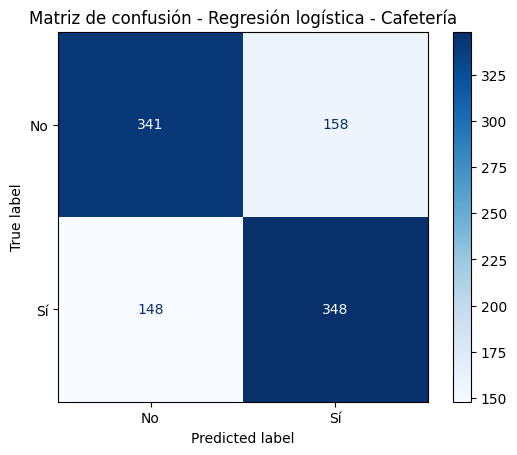

In [13]:
param_grid_logreg = [
    {'model__solver': ['liblinear'], 'model__penalty': ['l1', 'l2'], 'model__C': [0.01, 0.1, 1, 10]},
    {'model__solver': ['lbfgs'], 'model__penalty': ['l2'], 'model__C': [0.01, 0.1, 1, 10]},
]

grid_logreg_caf = ajustar_modelo(X_train_caf, y_train_caf,
                                  LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                                  param_grid_logreg, escalar=True)
grid_logreg_res = ajustar_modelo(X_train_res, y_train_res,
                                  LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                                  param_grid_logreg, escalar=True)

reporte_logreg_caf, pred_logreg_caf = evaluar_modelo(grid_logreg_caf, X_test_caf, y_test_caf, 'Regresión logística - Cafetería')

--- Regresión logística - Restaurante(<20) ---
Mejores hiperparámetros: {'model__C': 10, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
F1-macro en validación cruzada: 0.655
              precision    recall  f1-score   support

          No       0.60      0.41      0.49       203
          Sí       0.78      0.89      0.83       490

    accuracy                           0.75       693
   macro avg       0.69      0.65      0.66       693
weighted avg       0.73      0.75      0.73       693



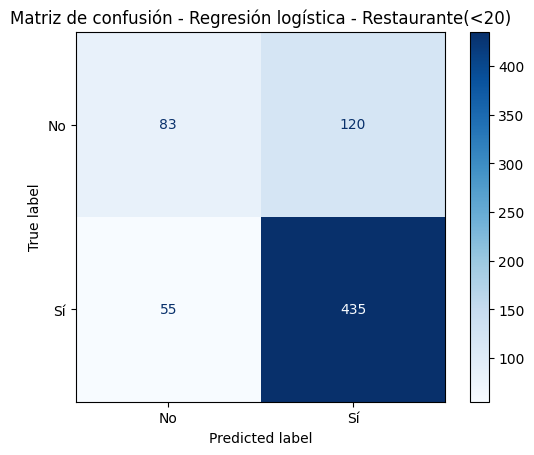

In [14]:
reporte_logreg_res, pred_logreg_res = evaluar_modelo(grid_logreg_res, X_test_res, y_test_res, 'Regresión logística - Restaurante(<20)')

**Cómo se lee.** En Cafetería, la regresión logística (`C=0.1`, penalización `l1`, solver `liblinear`) obtiene un F1-macro de 0.706 en validación cruzada y, sobre el conjunto de prueba, una exactitud de 0.69 con precisión y recall parecidos entre las dos clases (recall "No"=0.68, recall "Sí"=0.70). Como el problema está casi perfectamente balanceado (50.2% / 49.8%), el modelo no muestra ningún sesgo hacia una clase en particular.

En Restaurante(<20), el mejor modelo usa casi nada de regularización (`C=10`, `l2`, `lbfgs`), con un F1-macro de apenas 0.655 en validación cruzada. El comportamiento en prueba muestra con claridad el efecto del desbalance: el modelo predice bien la clase "Sí" (recall=0.89, precisión=0.78) pero le cuesta mucho identificar a quien **no** va a aceptar (recall "No"=0.41): de cada 10 personas que realmente rechazarían el cupón, el modelo apenas detecta a 4. Tiene sentido: con 70.8% de "Sí" en el entrenamiento, un modelo que casi siempre predice "Sí" ya obtiene una exactitud razonable, así que tiene poco incentivo para aprender a distinguir la clase minoritaria.

### 4.3. Árboles de decisión

Se explora la profundidad máxima, el número mínimo de observaciones por hoja y el criterio de división.

--- Árbol de decisión - Cafetería ---
Mejores hiperparámetros: {'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 1}
F1-macro en validación cruzada: 0.697
              precision    recall  f1-score   support

          No       0.70      0.66      0.68       499
          Sí       0.68      0.72      0.70       496

    accuracy                           0.69       995
   macro avg       0.69      0.69      0.69       995
weighted avg       0.69      0.69      0.69       995



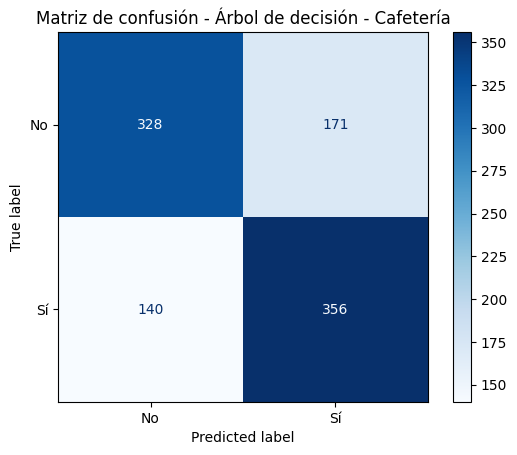

In [15]:
param_grid_tree = {
    'model__max_depth': [3, 5, 8, 12, None],
    'model__min_samples_leaf': [1, 5, 10, 20],
    'model__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_tree_caf = ajustar_modelo(X_train_caf, y_train_caf,
                                DecisionTreeClassifier(random_state=RANDOM_STATE),
                                param_grid_tree, escalar=False)
grid_tree_res = ajustar_modelo(X_train_res, y_train_res,
                                DecisionTreeClassifier(random_state=RANDOM_STATE),
                                param_grid_tree, escalar=False)

reporte_tree_caf, pred_tree_caf = evaluar_modelo(grid_tree_caf, X_test_caf, y_test_caf, 'Árbol de decisión - Cafetería')

--- Árbol de decisión - Restaurante(<20) ---
Mejores hiperparámetros: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 20}
F1-macro en validación cruzada: 0.648
              precision    recall  f1-score   support

          No       0.69      0.41      0.52       203
          Sí       0.79      0.92      0.85       490

    accuracy                           0.77       693
   macro avg       0.74      0.67      0.68       693
weighted avg       0.76      0.77      0.75       693



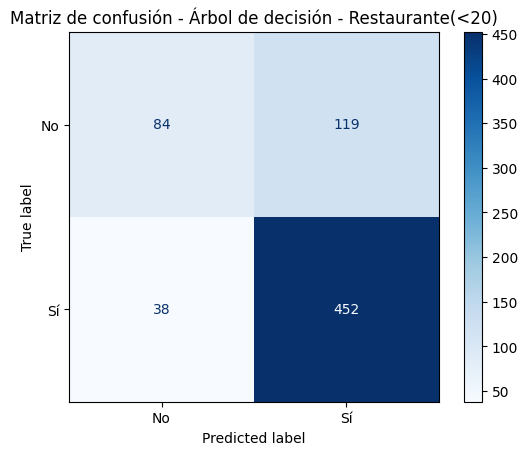

In [16]:
reporte_tree_res, pred_tree_res = evaluar_modelo(grid_tree_res, X_test_res, y_test_res, 'Árbol de decisión - Restaurante(<20)')

**Cómo se lee.** El árbol de Cafetería (`entropy`, profundidad 8, `min_samples_leaf=1`) obtiene un desempeño muy similar al de la regresión logística (F1-macro CV=0.697, F1-macro test=0.687): no hay una ventaja clara de uno sobre el otro en este cupón, aunque el árbol necesita bastante más profundidad para igualar al modelo lineal, señal de que aquí la relación entre variables no es tan simple como una combinación lineal.

Para Restaurante(<20), la búsqueda eligió `entropy`, profundidad 5 y hojas de al menos 20 observaciones -relativamente poco profundo y con hojas grandes-, lo cual sugiere que, con árboles más finos, el modelo empieza a sobreajustar el patrón mayoritario sin ganar generalización. El resultado en prueba (recall "No"=0.41, parecido al de la regresión logística) muestra el mismo problema frente al desbalance: tampoco logra identificar bien a quienes rechazan el cupón.

### 4.4. Random Forest

--- Random Forest - Cafetería ---
Mejores hiperparámetros: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
F1-macro en validación cruzada: 0.735
              precision    recall  f1-score   support

          No       0.75      0.73      0.74       499
          Sí       0.73      0.75      0.74       496

    accuracy                           0.74       995
   macro avg       0.74      0.74      0.74       995
weighted avg       0.74      0.74      0.74       995



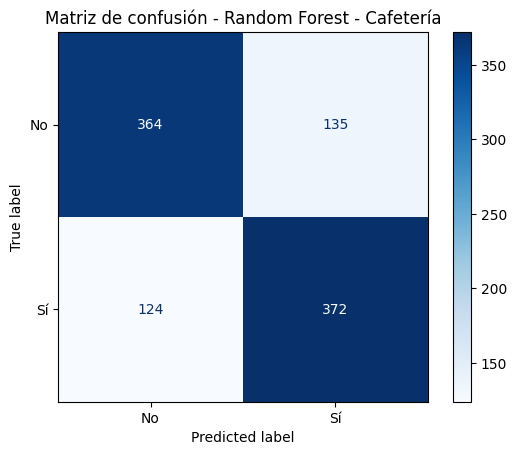

--- Random Forest - Restaurante(<20) ---
Mejores hiperparámetros: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
F1-macro en validación cruzada: 0.659
              precision    recall  f1-score   support

          No       0.70      0.38      0.50       203
          Sí       0.79      0.93      0.85       490

    accuracy                           0.77       693
   macro avg       0.74      0.66      0.67       693
weighted avg       0.76      0.77      0.75       693



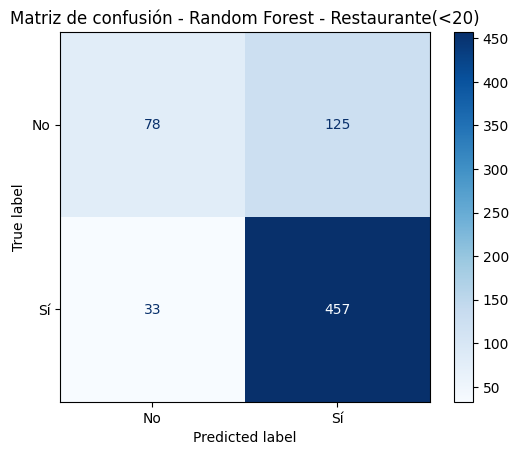

In [17]:
param_grid_rf = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [4, 6, 10],
    'model__min_samples_leaf': [1, 3, 5],
}

grid_rf_caf = ajustar_modelo(X_train_caf, y_train_caf,
                              RandomForestClassifier(random_state=RANDOM_STATE),
                              param_grid_rf, escalar=False)
grid_rf_res = ajustar_modelo(X_train_res, y_train_res,
                              RandomForestClassifier(random_state=RANDOM_STATE),
                              param_grid_rf, escalar=False)

reporte_rf_caf, pred_rf_caf = evaluar_modelo(grid_rf_caf, X_test_caf, y_test_caf,
                                              'Random Forest - Cafetería')
reporte_rf_res, pred_rf_res = evaluar_modelo(grid_rf_res, X_test_res, y_test_res,
                                              'Random Forest - Restaurante(<20)')

**Cómo se lee.** En Cafetería, Random Forest alcanza un F1-macro de 0.735 en validación cruzada y de aproximadamente 0.74 en prueba, con un desempeño muy equilibrado entre las dos clases (recall "No"=0.73 y recall "Sí"=0.75). Esto mejora ligeramente los resultados de la regresión logística y del árbol de decisión, lo que sugiere que el ensamble logra capturar interacciones no lineales entre las variables sin mostrar un sesgo importante hacia una clase.

Para Restaurante(<20), el mejor modelo usa 100 árboles, profundidad máxima de 10 y `min_samples_leaf=1`. Su F1-macro en validación cruzada es 0.659 y en prueba aproximadamente 0.67. Aunque la exactitud es 0.77, el recall de la clase "No" solo llega a 0.38, mientras que el de "Sí" alcanza 0.93. Por tanto, Random Forest sigue favoreciendo la clase mayoritaria y no resuelve por sí solo el desbalance: identifica bien a quienes aceptan el cupón, pero tiene dificultades para detectar a quienes lo rechazan.

En conjunto, Random Forest ofrece el mejor resultado de los tres modelos para Cafetería, pero en Restaurante(<20) la métrica más importante sigue siendo el F1-macro y el recall de la clase "No", no la exactitud global. Para mejorar esa clase sería necesario evaluar estrategias de balanceo, como `class_weight='balanced'` o SMOTE, tal y como se mostrará en el siguiente punto.

### 5. Balanceo de clases para Restaurante(<20)

In [18]:
# SMOTE se incluye dentro del pipeline para aplicarlo únicamente en cada pliegue de entrenamiento.
pipeline_rf_smote = ImbPipeline([
    ('preprocessor', construir_preprocesador(escalar=False)),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('model', RandomForestClassifier(random_state=RANDOM_STATE)),
])

param_grid_rf_smote = {
    'smote__sampling_strategy': [0.5, 1.0],
    'smote__k_neighbors': [3, 5],
    **param_grid_rf,
}

grid_rf_res_smote = GridSearchCV(
    estimator=pipeline_rf_smote,
    param_grid=param_grid_rf_smote,
    cv=CV,
    scoring='f1_macro',
    n_jobs=-1,
)
grid_rf_res_smote.fit(X_train_res, y_train_res)

pred_rf_res_smote = grid_rf_res_smote.predict(X_test_res)
reporte_rf_res_smote = classification_report(
    y_test_res, pred_rf_res_smote, output_dict=True, zero_division=0
)

reporte_rf_res_sin_balanceo = classification_report(
    y_test_res, pred_rf_res, output_dict=True, zero_division=0
)

comparacion_balanceo = pd.DataFrame({
    'RF sin balanceo': {
        'F1-macro CV': grid_rf_res.best_score_,
        'F1-macro test': reporte_rf_res_sin_balanceo['macro avg']['f1-score'],
        'Recall clase No': reporte_rf_res_sin_balanceo['No']['recall'],
        'Precision clase No': reporte_rf_res_sin_balanceo['No']['precision'],
    },
    'RF con SMOTE': {
        'F1-macro CV': grid_rf_res_smote.best_score_,
        'F1-macro test': reporte_rf_res_smote['macro avg']['f1-score'],
        'Recall clase No': reporte_rf_res_smote['No']['recall'],
        'Precision clase No': reporte_rf_res_smote['No']['precision'],
    },
}).round(3)

print('Mejores hiperparámetros con SMOTE:', grid_rf_res_smote.best_params_)
print('\nComparación sobre el conjunto de prueba:')
display(comparacion_balanceo)
print('\nReporte detallado - Random Forest con SMOTE:')
print(classification_report(y_test_res, pred_rf_res_smote, zero_division=0))

f1_sin_balanceo = reporte_rf_res_sin_balanceo['macro avg']['f1-score']
f1_con_smote = reporte_rf_res_smote['macro avg']['f1-score']
recall_no_sin_balanceo = reporte_rf_res_sin_balanceo['No']['recall']
recall_no_con_smote = reporte_rf_res_smote['No']['recall']

if f1_con_smote >= f1_sin_balanceo and recall_no_con_smote > recall_no_sin_balanceo:
    recomendacion_balanceo = 'Se recomienda SMOTE: mejora el F1-macro y el recall de la clase No.'
elif recall_no_con_smote > recall_no_sin_balanceo:
    recomendacion_balanceo = ('SMOTE mejora el recall de la clase No, pero reduce el F1-macro; '
                              'su uso depende del costo de no detectar rechazos.')
else:
    recomendacion_balanceo = ('No se recomienda SMOTE con este modelo: no mejora el recall de la clase No '
                              'y no ofrece una mejora global suficiente.')

print('\nRecomendación:', recomendacion_balanceo)

Mejores hiperparámetros con SMOTE: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 300, 'smote__k_neighbors': 3, 'smote__sampling_strategy': 1.0}

Comparación sobre el conjunto de prueba:


,RF sin balanceo,RF con SMOTE
F1-macro CV,0.659,0.689
F1-macro test,0.675,0.689
Recall clase No,0.384,0.473
Precision clase No,0.703,0.623



Reporte detallado - Random Forest con SMOTE:
              precision    recall  f1-score   support

          No       0.62      0.47      0.54       203
          Sí       0.80      0.88      0.84       490

    accuracy                           0.76       693
   macro avg       0.71      0.68      0.69       693
weighted avg       0.75      0.76      0.75       693


Recomendación: Se recomienda SMOTE: mejora el F1-macro y el recall de la clase No.


**Cómo se lee.** La comparación debe centrarse en el F1-macro y en el recall de la clase minoritaria `No`, porque el conjunto de Restaurante(<20) está desbalanceado. Si SMOTE aumenta el recall de `No` y mantiene o mejora el F1-macro de prueba, conviene recomendarlo: el modelo identifica a más conductores que rechazan el cupón sin sacrificar demasiado el desempeño global. Si el recall mejora pero el F1-macro disminuye de forma importante, el balanceo detecta más casos minoritarios a costa de más falsos positivos; en ese escenario la recomendación depende del costo de perder una recomendación frente al costo de contactar a alguien que probablemente no aceptará.

En todos los casos, SMOTE debe evaluarse dentro del pipeline y no antes de la validación cruzada. De esta forma, las observaciones sintéticas se generan solamente con los datos de entrenamiento de cada pliegue y no contaminan la evaluación.

Como puede observarse con los resultados, para una aplicación como Ruta Alpes, mandar notificaciones de cupones molestos o irrelevantes genera rechazo en los usuarios (molestia por notificaciones inoportunas mencionado en el caso de estudio). Por lo tanto, aunque la exactitud global baje un poco, conviene aplicar SMOTE porque la prioridad de la empresa seria no equivocarse al descartar usuarios y evitar enviar cupones de restaurantes a personas que claramente no los van a aprovechar.

### 6. Tabla comparativa de los modelos

In [19]:
reportes_modelos = {
    ('Regresión logística', 'Cafetería'): reporte_logreg_caf,
    ('Regresión logística', 'Restaurante(<20)'): reporte_logreg_res,
    ('Árbol de decisión', 'Cafetería'): reporte_tree_caf,
    ('Árbol de decisión', 'Restaurante(<20)'): reporte_tree_res,
    ('Random Forest', 'Cafetería'): reporte_rf_caf,
    ('Random Forest', 'Restaurante(<20)'): reporte_rf_res,
}

filas_comparacion = []
for (modelo, cupon), reporte in reportes_modelos.items():
    for clase in ['No', 'Sí', 'macro avg']:
        filas_comparacion.append({
            'Modelo': modelo,
            'Cupón': cupon,
            'Clase': clase,
            'Precisión': reporte[clase]['precision'],
            'Recall': reporte[clase]['recall'],
            'F1-score': reporte[clase]['f1-score'],
        })

tabla_comparativa = pd.DataFrame(filas_comparacion)
tabla_comparativa[['Precisión', 'Recall', 'F1-score']] = (
    tabla_comparativa[['Precisión', 'Recall', 'F1-score']].round(3)
)

print('Desempeño sobre el conjunto de prueba:')
display(tabla_comparativa)

tabla_macro = tabla_comparativa[
    tabla_comparativa['Clase'] == 'macro avg'
].sort_values(['Cupón', 'F1-score'], ascending=[True, False])

print('Comparación global ordenada por F1-score macro:')
display(tabla_macro)

Desempeño sobre el conjunto de prueba:


,Modelo,Cupón,Clase,Precisión,Recall,F1-score
0,Regresión logística,Cafetería,No,0.697,0.683,0.690
1,Regresión logística,Cafetería,Sí,0.688,0.702,0.695
2,Regresión logística,Cafetería,macro avg,0.693,0.692,0.692
3,Regresión logística,Restaurante(<20),No,0.601,0.409,0.487
4,Regresión logística,Restaurante(<20),Sí,0.784,0.888,0.833
5,Regresión logística,Restaurante(<20),macro avg,0.693,0.648,0.660
6,Árbol de decisión,Cafetería,No,0.701,0.657,0.678
7,Árbol de decisión,Cafetería,Sí,0.676,0.718,0.696
8,Árbol de decisión,Cafetería,macro avg,0.688,0.688,0.687
9,Árbol de decisión,Restaurante(<20),No,0.689,0.414,0.517


Comparación global ordenada por F1-score macro:


,Modelo,Cupón,Clase,Precisión,Recall,F1-score
14,Random Forest,Cafetería,macro avg,0.740,0.740,0.740
2,Regresión logística,Cafetería,macro avg,0.693,0.692,0.692
8,Árbol de decisión,Cafetería,macro avg,0.688,0.688,0.687
11,Árbol de decisión,Restaurante(<20),macro avg,0.740,0.668,0.684
17,Random Forest,Restaurante(<20),macro avg,0.744,0.658,0.675
5,Regresión logística,Restaurante(<20),macro avg,0.693,0.648,0.660


**Cómo se lee.** La fila `macro avg` da el peso promedio de las dos clases y es la referencia principal para comparar modelos, porque evita que la clase mayoritaria domine la conclusión. Las filas `No` y `Sí` permiten observar si un modelo funciona bien para una clase, pero mal para la otra.

En Cafetería, donde las clases están aproximadamente balanceadas, las métricas de ambas clases son similares y la comparación del F1-score macro es representativa del desempeño general. En Restaurante(<20), además del F1-score macro se debe revisar especialmente el recall de `No`: un modelo puede tener una exactitud alta y aun así identificar mal a las personas que rechazan el cupón. La tabla permite sustentar la elección del modelo con métricas de prueba y no únicamente con la exactitud.

**Elección de modelos:**

Para Cafetería: Como las clases están perfectamente balanceadas (~50/50), Random Forest se corona como el mejor modelo con un F1-macro de 0.740, superando de forma limpia a la Regresión Logística (0.692) y al Árbol de Decisión (0.687).

Para Restaurante(<20): La comparación global ordenada por F1-macro muestra que los modelos sin balancear se estancan alrededor de 0.66 - 0.68 debido al sesgo de la clase mayoritaria. Sin embargo, al incorporar SMOTE sobre Random Forest (ver Sección 5), el F1-macro sube a 0.689 y el recall de la clase "No" mejora de 0.384 a 0.473, logrando un mejor equilibrio práctico para la detección de rechazos.

### 8. Variables más relevantes

In [20]:
def nombres_variables_transformadas(grid):
    preprocessor = grid.best_estimator_.named_steps['preprocessor']
    if isinstance(preprocessor, Pipeline):
        preprocessor = preprocessor.named_steps['columnas']
    return preprocessor.get_feature_names_out()


def importancia_modelo(grid, modelo, cupon, n=10):
    nombres = nombres_variables_transformadas(grid)
    estimador = grid.best_estimator_.named_steps['model']

    if modelo == 'Regresión logística':
        valores = estimador.coef_[0]
        importancia = np.abs(valores)
        efecto = valores
    else:
        importancia = estimador.feature_importances_
        efecto = np.full(len(importancia), np.nan)

    resultado = pd.DataFrame({
        'Variable': nombres,
        'Importancia': importancia,
        'Efecto logístico': efecto,
    }).sort_values('Importancia', ascending=False).head(n)
    resultado.insert(0, 'Modelo', modelo)
    resultado.insert(1, 'Cupón', cupon)
    return resultado


grids_modelos = {
    ('Regresión logística', 'Cafetería'): grid_logreg_caf,
    ('Regresión logística', 'Restaurante(<20)'): grid_logreg_res,
    ('Árbol de decisión', 'Cafetería'): grid_tree_caf,
    ('Árbol de decisión', 'Restaurante(<20)'): grid_tree_res,
    ('Random Forest', 'Cafetería'): grid_rf_caf,
    ('Random Forest', 'Restaurante(<20)'): grid_rf_res,
}

filas_importancia = []
for (modelo, cupon), grid in grids_modelos.items():
    filas_importancia.append(importancia_modelo(grid, modelo, cupon))

tabla_importancia = pd.concat(filas_importancia, ignore_index=True)
tabla_importancia[['Importancia', 'Efecto logístico']] = (
    tabla_importancia[['Importancia', 'Efecto logístico']].round(4)
)

print('Diez variables más relevantes por modelo y tipo de cupón:')
display(tabla_importancia)

tabla_consenso = (
    tabla_importancia.groupby(['Cupón', 'Variable'])
    .agg(
        modelos_en_top=('Modelo', 'nunique'),
        importancia_promedio=('Importancia', 'mean'),
    )
    .reset_index()
    .sort_values(['Cupón', 'modelos_en_top', 'importancia_promedio'],
                 ascending=[True, False, False])
)

print('Variables que aparecen con mayor frecuencia entre las más relevantes:')
display(tabla_consenso.groupby('Cupón').head(10).round(4))

Diez variables más relevantes por modelo y tipo de cupón:

,Modelo,Cupón,Variable,Importancia,Efecto logístico
0,Regresión logística,Cafetería,ordinal__frecuencia_cafeteria,0.9495,0.9495
1,Regresión logística,Cafetería,nominal__destino_Sin lugar urgente,0.5062,0.5062
2,Regresión logística,Cafetería,nominal__vigencia_cupon_2 horas,0.3770,-0.3770
3,Regresión logística,Cafetería,ordinal__hora,0.3059,-0.3059
4,Regresión logística,Cafetería,nominal__misma_direccion_Sí,0.2317,0.2317
5,Regresión logística,Cafetería,ordinal__frecuencia_bar,0.1920,-0.1920
6,Regresión logística,Cafetería,nominal__tiempo_cupon_mayor_15min_Sí,0.1821,-0.1821
7,Regresión logística,Cafetería,nominal__acompanante_Amigo(s),0.1376,0.1376
8,Regresión logística,Cafetería,ordinal__educacion,0.1302,-0.1302
9,Regresión logística,Cafetería,nominal__ocupacion_Profesionales y Técnicos de...,0.1256,0.1256


Variables que aparecen con mayor frecuencia entre las más relevantes:


,Cupón,Variable,modelos_en_top,importancia_promedio
11,Cafetería,ordinal__frecuencia_cafeteria,3,0.4864
6,Cafetería,nominal__vigencia_cupon_2 horas,3,0.1639
15,Cafetería,ordinal__hora,3,0.1353
10,Cafetería,ordinal__frecuencia_bar,3,0.0877
1,Cafetería,nominal__destino_Sin lugar urgente,2,0.2736
9,Cafetería,ordinal__educacion,2,0.0838
16,Cafetería,ordinal__ingreso,2,0.0610
12,Cafetería,ordinal__frecuencia_comida_para_llevar,2,0.0424
14,Cafetería,ordinal__frecuencia_restaurante_menos_20,2,0.0344
2,Cafetería,nominal__misma_direccion_Sí,1,0.2317


**Cómo se lee.** En regresión logística, `Importancia` es el valor absoluto del coeficiente: cuanto mayor sea, mayor es la influencia de la variable en la predicción. `Efecto logístico` conserva el signo del coeficiente; un valor positivo empuja la predicción hacia la clase positiva y uno negativo la aleja. En el árbol de decisión y Random Forest, `Importancia` corresponde a la reducción acumulada de impureza atribuida a cada variable.

Las variables aparecen con nombres como `ordinal__edad` o `nominal__destino_Centro`, porque las variables categóricas fueron transformadas por el pipeline. En consecuencia, una categoría específica de una variable nominal puede aparecer como relevante de manera independiente. La tabla de consenso ayuda a distinguir las variables que aparecen repetidamente entre las más importantes en varios modelos, en lugar de basar la conclusión en un solo algoritmo.

La importancia no demuestra causalidad: indica asociación útil para la predicción dentro de estos datos. Las variables identificadas deben interpretarse junto con el contexto de Ruta Alpes y no como evidencia de que modificar una variable necesariamente causaría que el conductor aceptara o rechazara el cupón. 

### 9. Análisis de resultados

**¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

R/ Para el cupón de Cafetería, las variables que aparecen con mayor frecuencia entre las más relevantes son la frecuencia de consumo de cafetería, la vigencia del cupón, la hora y la frecuencia de consumo en bares. Para Restaurante(<20), las variables con mayor consenso son la vigencia del cupón, la hora y el clima soleado. También aparecen variables relacionadas con el destino, el acompañante, el ingreso y el tiempo de desplazamiento. Estos resultados representan asociaciones predictivas, no relaciones causales. Estos resultados están respaldados por la tabla de concenso de la parte 8, en donde se puede apreciar que todos los modelos incluyeron a estas variables como relevantes para predecir la aceptación de cada tipo de cupón

**¿Existen variables que podrían ser redundantes o poco informativas?

R/ Sí. direccion_opuesta y misma_direccion contenían información perfectamente redundante, porque eran variables complementarias. Por ello se conservó misma_direccion y se eliminó direccion_opuesta. También se eliminó vehiculo porque tenía más del 99% de valores nulos, lo que hacía poco confiable su uso. Finalmente, tiempo_cupon_mayor_5min se eliminó porque tenía varianza cero: todos sus valores eran "Sí" y, por tanto, no permitía diferenciar observaciones.

**¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿A qué atribuye esa diferencia?

R/ Sí, el desempeño y el comportamiento de los modelos difieren. En Cafetería, las clases están aproximadamente balanceadas, con cerca del 50% de casos "Sí" y 50% de casos "No". En Restaurante(<20), la distribución es desigual: aproximadamente el 70.8% de los casos corresponde a "Sí" y el 29.2% a "No" (ver Sección 2 y la partición de entrenamiento). Este desbalance hace que los modelos tiendan a favorecer la clase mayoritaria y tengan dificultades para identificar los casos "No". Esto se refleja en un recall bajo para esa clase, aproximadamente entre 38% y 41% en los modelos sin balanceo.

**¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general, así como el recall de la clase minoritaria.

R/ Sí, aplicar SMOTE mejoró el desempeño global y la detección de la clase minoritaria. El F1-macro sobre prueba aumentó de 0.675 a 0.689, mientras que el recall de la clase "No" pasó de 0.384 a 0.473, un incremento de aproximadamente 8.9 puntos porcentuales. Esto significa que el modelo identificó una mayor cantidad de conductores que no aceptarían el cupón. Sin embargo, la precisión de la clase "No" disminuyó de 0.703 a 0.623, por lo que el aumento del recall produjo también más falsos positivos. En este caso sí se recomienda SMOTE, porque mejora el F1-macro y el recall de la clase minoritaria, que son métricas importantes para evitar enviar ofertas poco relevantes.

**A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.

R/ En el modelo Random Forest, las variables más relevantes para predecir la aceptación del cupón de Cafetería son principalmente la frecuencia de consumo de cafetería, la vigencia del cupón, la hora del día y la frecuencia de consumo en bares. Estas variables aparecen de forma consistente entre las más importantes y sugieren que tanto los hábitos previos del conductor como el contexto temporal de la oferta influyen en la predicción.Para Restaurante(<20), Random Forest identifica como variables relevantes la vigencia del cupón, la hora, el clima soleado, el tiempo estimado del cupón y el acompañante. Esto indica que, para este tipo de cupón, las condiciones del desplazamiento y el contexto en el que se presenta la oferta tienen un peso importante en la predicción. La utilidad de esta interpretación es que permite a Ruta Alpes conocer qué información debería considerar al momento de recomendar cupones. Por ejemplo, el sistema podría tener en cuenta la hora, la vigencia disponible, el tiempo de desplazamiento, el clima y el historial de consumo del conductor para decidir qué oferta mostrar. Sin embargo, la importancia de variables en Random Forest no representa una regla directa ni indica por sí sola si una variable aumenta o disminuye la probabilidad de aceptación. Por ejemplo, que clima_Soleado sea importante para Restaurante(<20) significa que ayuda al modelo a distinguir entre casos de aceptación y rechazo, pero no demuestra que el clima soleado cause una mayor aceptación. Además, Random Forest combina muchos árboles, por lo que sus decisiones son más difíciles de explicar mediante una única regla. Las importancias también pueden verse afectadas cuando existen variables relacionadas entre sí.

**¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

R/ El modelo Random Forest puede integrarse en la aplicación como un componente de recomendación. Mientrás el conductor realiza su recorrido, la aplicación recopila características disponibles en tiempo real, como la hora, el destino, el clima, el tiempo estimado para llegar y la vigencia del cupón. Estas variables se transforman usando el preprocesador utilizado durante el entrenamiento y se envian al modelo. RandomForest calcula la probabilidad de aceptación para cada tipo de cupón y la aplicación puede mostrar la oferta de mayor probabilidad, siempre que se supere cierto umbral y no represente una distracción o un estorbo para el conductor. Si las probabilidades no son lo suficientemente altas, la aplicación no deberia enviar ninguna oferta de cupón.

**¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

R/ Un sistema automático que decide qué ofertas mostrar según el perfil demográfico del conductor puede presentar varias limitaciones. En primer lugar, puede reproducir sesgos presentes en los datos de entrenamiento. Si ciertos grupos demográficos están poco representados o históricamente aceptaron menos cupones, el modelo podría aprender a mostrarles menos ofertas, aunque sus preferencias individuales sean diferentes. Además, variables como la edad, el género, el estado civil, la ocupación o el nivel de ingreso pueden producir estereotipos. El modelo podría asociar de manera injustificada ciertas características demográficas con la aceptación o el rechazo de un cupón. Por ejemplo, podría asumir que una persona de determinado grupo no está interesada en un restaurante, aunque sus hábitos reales indiquen lo contrario.

**¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

R/ En los datos pueden existir sesgos de representación si algunos grupos de edad, género, estado civil, ocupación o nivel de ingreso aparecen con mucha mayor frecuencia que otros. En ese caso, el modelo puede aprender principalmente los patrones de los grupos mayoritarios y producir predicciones menos confiables para los grupos con pocos ejemplos. También puede existir un sesgo histórico. Si en el pasado ciertas personas recibieron menos ofertas o tuvieron menos oportunidades de aceptar cupones, el modelo podría interpretar ese comportamiento histórico como una preferencia real y reproducirlo. Esto puede crear un ciclo en el que algunos grupos reciben cada vez menos ofertas y, por lo tanto, generan menos datos para corregir el problema. Si esta personalización se utilizara para otro fin como por ejemplo precios dinámicos, las consecuencias serían más graves. El sistema podría cobrar precios diferentes a personas con características demográficas similares o penalizar indirectamente a determinados grupos por su perfil, ubicación o nivel de ingreso. Esto podría producir discriminación económica, falta de transparencia y pérdida de confianza. Una recomendación de cupón poco relevante puede ser molesta, pero un precio diferente puede afectar directamente el acceso de una persona a un servicio.

### 10. Predicciones sobre Lab3_datos_Prueba

In [21]:
prueba = pd.read_excel('Data/Lab3_datos_Prueba.xlsx')
cafeteria_test = prueba[prueba['cupon'] == 'Cafetería'].drop(columns='cupon').reset_index(drop=True)
restaurante_test = prueba[prueba['cupon'] == 'Restaurante(<20)'].drop(columns='cupon').reset_index(drop=True)

#El mejor modelo para cafeteria fue random forest
predicciones_cafeteria = grid_rf_caf.predict(cafeteria_test)

#El mejor modelo para restaurante fue random forest con SMOTE
predicciones_restaurante = grid_rf_res_smote.predict(restaurante_test)

# Asignar las predicciones de vuelta al dataframe original de prueba usando los índices o filtros originales:
prueba.loc[prueba['cupon'] == 'Cafetería', 'acepta_cupon'] = predicciones_cafeteria
prueba.loc[prueba['cupon'] == 'Restaurante(<20)', 'acepta_cupon'] = predicciones_restaurante

# Archivo final con las predicciones
prueba.to_csv('Data/Lab3_datos_Prueba.csv', index=False)


Para generar las predicciones se seleccionó el mejor modelo para cada tipo de cupón según el F1-macro obtenido sobre el conjunto de prueba. Para Cafetería se utilizó Random Forest, porque alcanzó el mejor desempeño global entre los modelos evaluados. Para Restaurante(<20) se utilizó Random Forest con SMOTE, ya que mejoró el F1-macro de 0.675 a 0.689 y aumentó el recall de la clase minoritaria No de 0.384 a 0.473. Esta última mejora es importante porque permite identificar una mayor cantidad de conductores que probablemente no aceptarían el cupón.

## Uso de herramientas de IA generativa

### Declaración del uso

Se utilizó Claude y Gemini. Las herramientas se emplearón para aclarar conceptos de aprendizaje automático, proponer estructuras iniciales de código, revisar posibles errores de implementación y mejorar la redacción técnica de algunas interpretaciones. La responsabilidad final sobre el código, los resultados, el análisis y las conclusiones corresponde a los integrantes del equipo.

### Prompts principales utilizados

Los prompts que influyeron directamente en el trabajo fueron:

- "Explícame cómo funciona un Random Forest en comparación con un árbol de decisión individual y regresión logística para este problema de clasificación de cupones."
- "¿Cómo se debe implementar correctamente SMOTE en un pipeline de Scikit-learn junto con GridSearchCV para evitar fugas de datos en validación cruzada?"
- "Identifica las variables más relevantes para los modelos y explica cómo interpretar la tabla de consenso."
- "Analiza las respuestas que puse en las sección de resultados y ayúdame a mejorar la redacción de las respuestas de la sección de análisis de resultados del laboratorio, justificando más a profundidad el balanceo de clases y las limitaciones del uso de variables demográficas."

### Análisis crítico del resultado

La asistencia fue útil para estructurar los 3 tipos de modelos bajo una estructura en común, de tal manera que se facilitara la implementación de cada modelo mediante la reutilización de un esquema definido. También, fue muy útil por las explicaciones técnicas y teóricas que nos dió, lo cual nos permitió entender más lo que se realizó en cada parte del laboratorio y encontrar la relación entre el contexto del ejercicio y todo lo que se implementó, por ejemplo las sugerencias para conectar las métricas técnicas (como el recall de la clase minoritaria) con la realidad de negocio de Ruta Alpes (evitar notificaciones molestas) resultaron muy acertadas.

Las respuestas generadas no se aceptaron automáticamente. Se verificaron ejecutando las celdas y contrastando los valores obtenidos en el notebook junto con la teoría y el contexto del problema. 

Un error que se precisó fue que la importancia de una variable en todos los modelos indica utilidad predictiva, pero no demuestra causalidad ni indica por sí sola la dirección del efecto. Por ejemplo, esta corrección fue importante al interpretar `clima_Soleado` para Restaurante(<20): la variable ayuda a distinguir entre casos, pero no permite afirmar que el clima soleado cause una mayor aceptación.

Los conceptos del curso utilizados para evaluar y mejorar las respuestas fueron validación cruzada estratificada, separación entre entrenamiento y prueba, métricas por clase, desbalance de clases, prevención de fuga de información, pipelines, SMOTE e interpretación de importancia de variables.

### Aportes propios del equipo

El equipo realizó la exploración, limpieza y preparación de los datos; definió las variables ordinales, nominales y numéricas; seleccionó los modelos y las grillas de hiperparámetros; ejecutó el notebook; revisó las métricas; comparó los modelos; y decidió las conclusiones presentadas. Además, se modificaron y adaptaron las propuestas iniciales de código proporcionados por la IA para integrarlos de manera fluida en la estructura del notebook, se usó `f1_macro` como criterio de selección,se aplicó SMOTE dentro de un `ImbPipeline`, se conservó el conjunto de prueba sin balancear y se analizó por separado las clases `No` y `Sí`, igualmente la toma de decisiones finales sobre qué modelo elegir para cada tipo de cupón fueron realizadas de forma autónoma. Finalmente, se redactaron con criterio propio las respuestas analíticas, vinculándolas directamente con los resultados obtenidos en las ejecuciones, se uso la IA para ampliar más las explicaciones y tener una mejor comprensión de conceptos.

El proceso permitió comprender que la selección de un modelo no debe basarse únicamente en la accuracy, especialmente cuando existe desbalance de clases. Aprendimos a utilizar la validación cruzada estratificada para comparar diferentes configuraciones de hiperparámetros y seleccionar la que obtiene el mejor F1-macro promedio. También comprendimos la importancia de aplicar el preprocesamiento y SMOTE dentro de un pipeline para evitar fuga de información durante la validación cruzada. Además, aprendimos a interpretar las métricas por clase, particularmente el recall de la clase minoritaria, y a reconocer que una variable importante para la predicción no necesariamente implica una relación causal. Finalmente, entendimos que las decisiones de modelado deben relacionarse con el contexto de negocio de Ruta Alpes y con las consecuencias prácticas de los falsos positivos y falsos negativos.